Loading data...
Preprocessing data and creating features...
Building and training the LSTM model...


/tmp/ipython-input-1494247759.py:34: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill', inplace=True)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.1091 - val_loss: 0.0069
Epoch 2/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0068 - val_loss: 0.0010
Epoch 3/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0046 - val_loss: 0.0018
Epoch 4/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0041 - val_loss: 0.0011
Epoch 5/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0039 - val_loss: 8.8582e-04
Epoch 6/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0035 - val_loss: 0.0011
Epoch 7/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0033 - val_loss: 0.0013
Epoch 8/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0033 - val_loss: 7.9529e-04
Epoch 9/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.0030 - val_loss: 8.1321e-04
Epoch 10/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0029 - val_loss: 7.8322e-04
Epoch 11/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0027 - val_loss: 9.6895e-04
Epoch 12/20
234/234 ━━━━━━━━━━

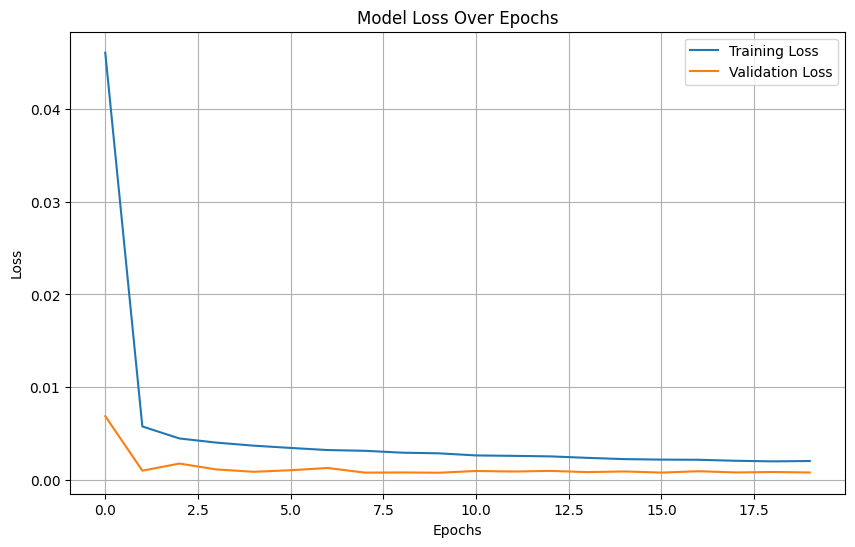

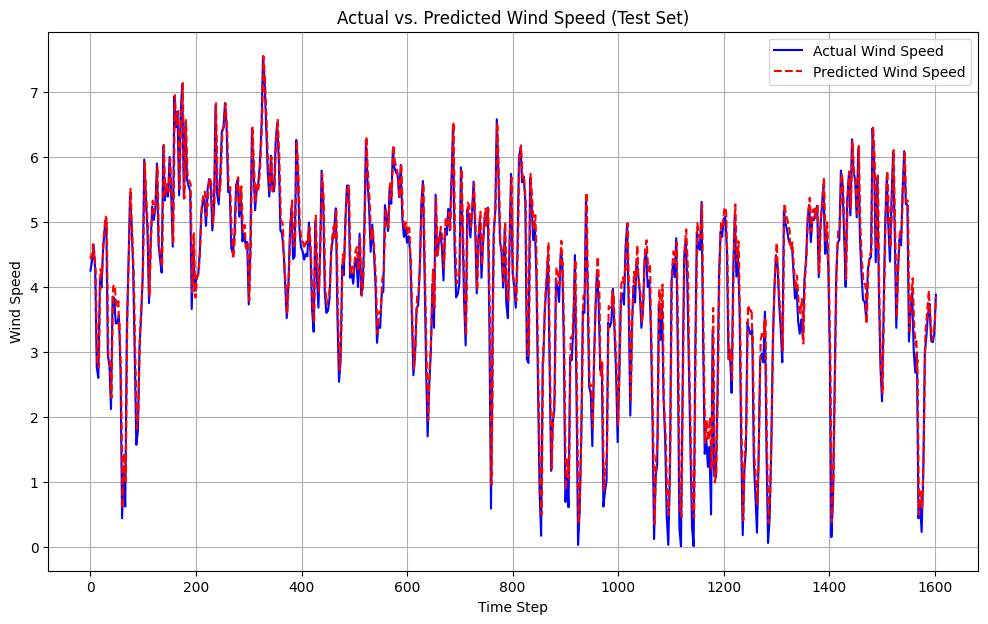

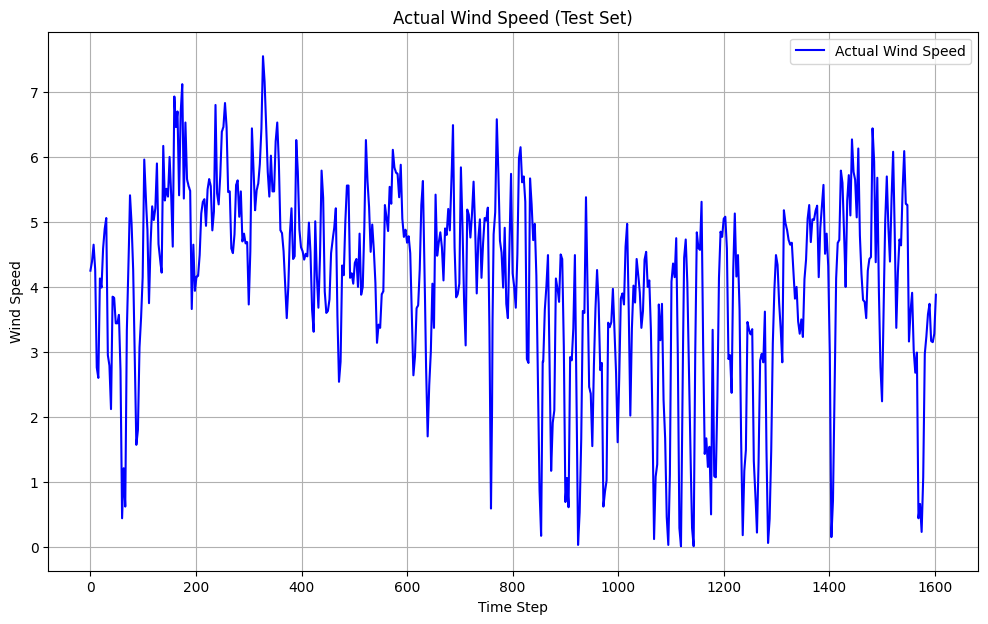

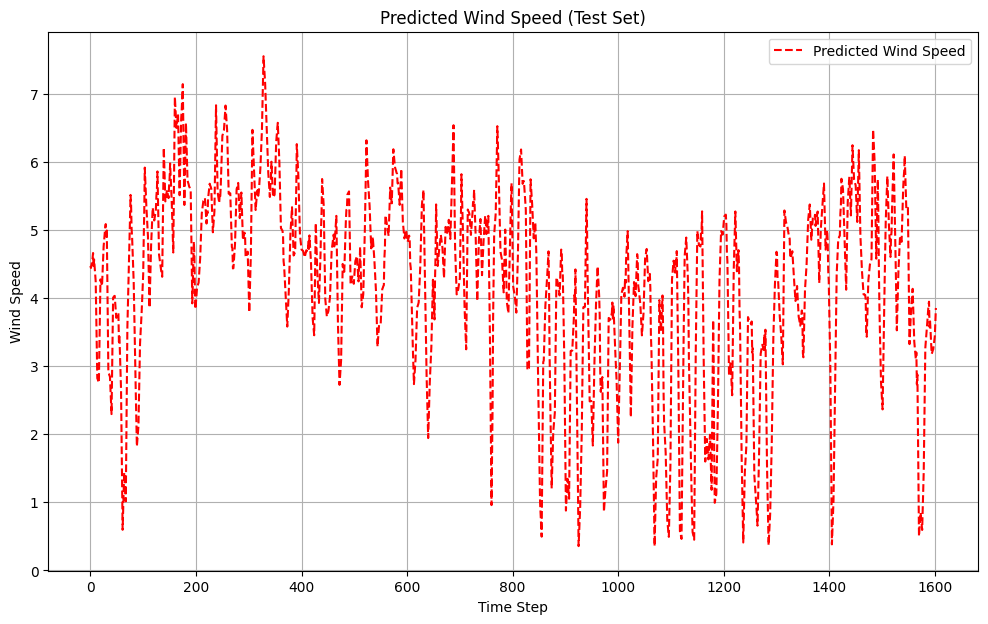

In [ ]:
# This script performs wind speed forecasting using a Deep Learning model.
# It processes historical wind data, trains an LSTM model, and evaluates its performance.

# 1. Import necessary libraries
import pandas as pd # For data manipulation and analysis.
import numpy as np # For numerical operations, especially with arrays.
import matplotlib.pyplot as plt # For creating static, interactive, and animated visualizations.
from sklearn.preprocessing import MinMaxScaler # To scale features to a given range.
from sklearn.metrics import mean_absolute_error, mean_squared_error # To evaluate model performance.
import tensorflow as tf # The core library for Deep Learning.
from tensorflow.keras.models import Sequential # To build a simple, layer-by-layer model.
from tensorflow.keras.layers import LSTM, Dense, Dropout # Key layers for the model.

# 2. Load the dataset
# Assuming 'tibau_wind_data.csv' is in the same directory as the script.
print("Loading data...")
try:
    # Read the CSV without a header and assign column names.
    df = pd.read_csv('tibau_wind_data.csv', header=None, names=['timestamp', 'wind speed', 'wind direction'])
except FileNotFoundError:
    print("Error: The file 'tibau_wind_data.csv' was not found.")
    exit() # Exit the script if the file is not found.

# 3. Data Preprocessing and Feature Engineering
print("Preprocessing data and creating features...")

# Convert the 'timestamp' column to datetime objects for time-series analysis.
df['timestamp'] = pd.to_datetime(df['timestamp'])
# Set the timestamp as the DataFrame index for easier time-based operations.
df.set_index('timestamp', inplace=True)

# Handle missing values (if any) by filling them with the previous valid observation.
# This is a simple imputation method suitable for time-series data.
df.fillna(method='ffill', inplace=True)

# Feature Engineering: Extracting time-based features from the timestamp.
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek
df['month'] = df.index.month

# Feature Engineering: Create a lagged feature of wind speed.
# The model will use the previous hour's wind speed to predict the current one.
# This is a crucial feature for time-series forecasting.
df['wind speed_lag_1'] = df['wind speed'].shift(1)
# Remove the first row which will have a NaN value due to the shift.
df.dropna(inplace=True)

# Prepare the data for the model.
# We will use 'wind speed_lag_1', 'hour', 'day_of_week', and 'month' as features.
# The target variable is 'wind speed'.
features = ['wind speed_lag_1', 'hour', 'day_of_week', 'month']
target = 'wind speed'

# 4. Data Scaling and Splitting (Corrected)
# A key fix: We will now scale the features and the target separately.
# This is more robust and prevents the inverse transform error.
feature_scaler = MinMaxScaler(feature_range=(0, 1))
target_scaler = MinMaxScaler(feature_range=(0, 1))

# Scale the features
scaled_features = feature_scaler.fit_transform(df[features])
# Reshape the target to a 2D array before scaling
scaled_target = target_scaler.fit_transform(df[[target]])

# Combine the scaled features and target into a single array for splitting.
scaled_data = np.hstack((scaled_features, scaled_target))

# Split the data into training, validation, and test sets.
# We use a chronological split (by index) which is essential for time-series data.
# 70% for training, 15% for validation, and 15% for testing.
train_size = int(len(scaled_data) * 0.70)
val_size = int(len(scaled_data) * 0.15)
train_data = scaled_data[0:train_size, :]
val_data = scaled_data[train_size:train_size + val_size, :]
test_data = scaled_data[train_size + val_size:len(scaled_data), :]

# Define a function to create sequences for the LSTM model.
# LSTMs require data to be in a specific 3D format: [samples, timesteps, features].
# Since our data is already hourly, we can use a single timestep for simplicity.
def create_sequences(data, n_features):
    X, y = [], []
    for i in range(len(data)):
        # The first n_features columns are the input features (X).
        # The last column is the target variable (y).
        X.append(data[i, :-1])
        y.append(data[i, -1])
    return np.array(X), np.array(y)

# Create sequences for each dataset.
X_train, y_train = create_sequences(train_data, len(features))
X_val, y_val = create_sequences(val_data, len(features))
X_test, y_test = create_sequences(test_data, len(features))

# Reshape the input data to the required 3D format for LSTM layers.
# The shape is (number of samples, timesteps, number of features).
# Here, timesteps = 1 because we are using a single lagged feature.
X_train = np.reshape(X_train, (X_train.shape[0], 1, X_train.shape[1]))
X_val = np.reshape(X_val, (X_val.shape[0], 1, X_val.shape[1]))
X_test = np.reshape(X_test, (X_test.shape[0], 1, X_test.shape[1]))

# 5. Build and Train the LSTM Model
print("Building and training the LSTM model...")

# Define the LSTM model architecture.
model = Sequential()
# Add the first LSTM layer with 50 units. 'return_sequences=True' is used
# when stacking LSTM layers.
model.add(LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dropout(0.2)) # A dropout layer to prevent overfitting.
# Add a second LSTM layer.
model.add(LSTM(50))
model.add(Dropout(0.2))
# Add the final Dense layer with 1 unit, as we are predicting a single value (wind speed).
model.add(Dense(1))

# Compile the model.
# 'adam' is a popular and effective optimizer.
# 'mse' (Mean Squared Error) is used as the loss function for regression tasks.
model.compile(optimizer='adam', loss='mse')

# Train the model.
# 'epochs' is the number of times the model will go through the entire training dataset.
# 'batch_size' is the number of samples per gradient update.
# 'validation_data' is used to monitor the loss on a separate dataset to prevent overfitting.
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_val, y_val), verbose=1)

# 6. Model Evaluation (Corrected)
print("Evaluating the model on the test set...")

# Make predictions on the test data.
y_pred = model.predict(X_test)

# The fix: We now use the target_scaler, which was only fitted on the target values,
# to inverse transform our predictions and the actual test values. This is correct
# and robust.
y_pred_unscaled = target_scaler.inverse_transform(y_pred)
y_test_unscaled = target_scaler.inverse_transform(y_test.reshape(-1, 1))

# Calculate and print the evaluation metrics.
mae = mean_absolute_error(y_test_unscaled, y_pred_unscaled)
mse = mean_squared_error(y_test_unscaled, y_pred_unscaled)
rmse = np.sqrt(mse)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# 7. Visualization
print("Generating visualizations...")

# Plot the training and validation loss over epochs.
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Plot the actual vs. predicted wind speed for a portion of the test set.
plt.figure(figsize=(12, 7))
# Plot the actual wind speed.
plt.plot(y_test_unscaled, label='Actual Wind Speed', color='blue')
# Plot the predicted wind speed.
plt.plot(y_pred_unscaled, label='Predicted Wind Speed', color='red', linestyle='--')
plt.title('Actual vs. Predicted Wind Speed (Test Set)')
plt.xlabel('Time Step')
plt.ylabel('Wind Speed')
plt.legend()
plt.grid(True)
plt.show()

# Plot actual wind speed separately
plt.figure(figsize=(12, 7))
plt.plot(y_test_unscaled, label='Actual Wind Speed', color='blue')
plt.title('Actual Wind Speed (Test Set)')
plt.xlabel('Time Step')
plt.ylabel('Wind Speed')
plt.legend()
plt.grid(True)
plt.show()

# Plot predicted wind speed separately
plt.figure(figsize=(12, 7))
plt.plot(y_pred_unscaled, label='Predicted Wind Speed', color='red', linestyle='--')
plt.title('Predicted Wind Speed (Test Set)')
plt.xlabel('Time Step')
plt.ylabel('Wind Speed')
plt.legend()
plt.grid(True)
plt.show()